# Anomalie de nuit sur le SPY : la nuit rapporte-t-elle plus que la séance ?

**Source.** Article de recherche QuantConnect n° 15296, « Overnight Anomaly », qui renvoie à la fiche Quantpedia du même nom. La règle de l'article achète le SPY à la clôture et le revend à l'ouverture suivante, chaque jour de bourse. L'article conclut que ce rendement de nuit disparaît une fois payés les frais de deux ordres par jour.

**Ce que fait ce carnet**, sur les cours journaliers du SPY des données LEAN (décembre 2007 → juillet 2026) :

1. il découpe chaque journée en deux moitiés, la nuit (de la clôture de la veille à l'ouverture) et la séance (de l'ouverture à la clôture), et compare leurs rendements ;
2. il calcule le coût d'aller-retour qui ramène à zéro le rendement moyen de nuit, et le compare au barème de frais par action du courtier IB tel que Lean le modélise ;
3. il regarde si le résultat tient d'une sous-période à l'autre ;
4. il rappelle la règle de décision des backtests, écrite avant leur lancement, puis donne le verdict.

Les backtests QC Cloud du projet (`main.py`, données à la minute, ordres MOC et MOO) portent la mesure avec frais ; le carnet en donne l'explication.

In [1]:
# Chargement des cours journaliers du SPY par QuantBook (données LEAN)
from AlgorithmImports import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')

qb = QuantBook()
spy = qb.add_equity("SPY", Resolution.DAILY).symbol

# Cours ajustés des dividendes (réglage par défaut) : le dividende détaché à l'ouverture
# est donc compté dans la nuit, comme pour qui détient le titre à la clôture de la veille.
history = qb.history(spy, datetime(2007, 12, 1), datetime(2026, 8, 1), Resolution.DAILY)
bars = history.loc[spy][["open", "close"]].copy()
# L'index porte la fin de la barre (16 h) : on ne garde que la date de séance
bars.index = pd.to_datetime(bars.index).normalize()
bars = bars[bars.index <= "2026-07-31"]
print(f"{len(bars)} séances, du {bars.index[0].date()} au {bars.index[-1].date()}")
print(bars.head(3).round(2))

4694 séances, du 2007-12-03 au 2026-07-31
              open   close
time                      
2007-12-03  104.73  104.37
2007-12-04  103.65  103.44
2007-12-05  104.55  105.17


### Lecture du résultat

Les données LEAN donnent 4 694 séances, du 3 décembre 2007 au 31 juillet 2026, en cours ajustés des dividendes et des divisions. Le carnet commence donc quatre ans après la fenêtre A des backtests (2004-2015) : ses deux sous-périodes, 2008-2015 et 2016-2026, recouvrent la fin de A et toute la fenêtre B.

## 1. Découper la journée en deux moitiés

Pour chaque séance $t$, avec $O_t$ l'ouverture et $C_t$ la clôture :

- rendement de nuit : $r^{nuit}_t = O_t / C_{t-1} - 1$, ce que gagne qui achète à la clôture et revend à l'ouverture ;
- rendement de séance : $r^{séance}_t = C_t / O_t - 1$, le miroir ;
- rendement du titre détenu : $C_t / C_{t-1} - 1$.

Les deux moitiés se composent exactement : $(1 + r^{nuit}_t)(1 + r^{séance}_t) = C_t / C_{t-1}$. La somme des rendements logarithmiques de la nuit et de la séance vaut donc celle du titre détenu, ce qui permet de dire quelle part du rendement total chaque moitié porte.

In [2]:
# Rendement de nuit (clôture de la veille -> ouverture) et de séance (ouverture -> clôture)
r_night = bars["open"] / bars["close"].shift(1) - 1
r_day = bars["close"] / bars["open"] - 1
r_hold = bars["close"] / bars["close"].shift(1) - 1
returns = pd.DataFrame({"nuit": r_night, "séance": r_day, "détenu": r_hold}).dropna()


def summary(r: pd.DataFrame) -> pd.DataFrame:
    """Statistiques annualisées sur 252 séances, taux sans risque nul."""
    years = len(r) / 252
    wealth = (1 + r).cumprod()
    return pd.DataFrame({
        "moyenne par jour (pb)": r.mean() * 1e4,
        "CAGR (%)": (wealth.iloc[-1] ** (1 / years) - 1) * 100,
        "volatilité (%)": r.std() * np.sqrt(252) * 100,
        "Sharpe": r.mean() / r.std() * np.sqrt(252),
        "perte max (%)": (wealth / wealth.cummax() - 1).min() * 100,
        "jours positifs (%)": (r > 0).mean() * 100,
    })


print(summary(returns).round(2))
# Part de chaque moitié dans le rendement logarithmique total du titre détenu
log_total = np.log1p(returns["détenu"]).sum()
for col in ("nuit", "séance"):
    print(f"part de la {col} dans le rendement log total : {np.log1p(returns[col]).sum() / log_total:.1%}")

        moyenne par jour (pb)  CAGR (%)  volatilité (%)  Sharpe  \
nuit                     3.15      7.48           12.04    0.66   
séance                   1.79      3.40           15.23    0.30   
détenu                   4.97     11.13           19.78    0.63   

        perte max (%)  jours positifs (%)  
nuit           -29.41               55.27  
séance         -42.08               53.95  
détenu         -53.89               55.06  
part de la nuit dans le rendement log total : 68.4%
part de la séance dans le rendement log total : 31.6%


### Lecture du résultat

Sur la fenêtre entière, la nuit rapporte 3,15 pb par jour contre 1,79 pb pour la séance, et porte 68,4 % du rendement logarithmique du titre détenu. Elle le fait avec moins de risque : volatilité de 12,0 % contre 15,2 % en séance et 19,8 % pour le titre détenu, perte maximale de −29,4 % contre −53,9 % pour le titre détenu. D'où un Sharpe de la nuit (0,66) un peu au-dessus de celui du titre détenu (0,63), alors que son CAGR est plus bas (7,5 % contre 11,1 %). Avant frais, l'anomalie existe : la moitié nocturne de la journée est la plus rentable des deux, et la moins risquée.

## 2. Le coût qui annule le rendement de nuit

La règle passe deux ordres par jour. Dans Lean, le barème du courtier IB pour les actions américaines coûte 0,005 $ par action, avec un minimum de 1 $ par ordre. Au-delà de 200 actions par ordre, le coût d'un aller-retour, rapporté au montant engagé, vaut donc environ $0{,}01 / P$, où $P$ est le cours : il baisse quand le cours monte.

La cellule suivante calcule ce coût séance par séance pour un portefeuille de 100 000 $ engagé à 98 %, comme dans `main.py`, puis le rendement de nuit net des frais. Elle ajoute un glissement par ordre de 0,5, 1 et 2 points de base (pb) pour voir à partir de quand la nuit ne rapporte plus rien. Les ordres MOC et MOO se remplissent au prix d'enchère, sans écart acheteur-vendeur : le glissement est une sensibilité, pas une hypothèse du backtest.

In [3]:
# Frais d'un aller-retour (achat + vente) en fraction du montant engagé, barème par action de Lean
capital = 100_000 * 0.98
shares = np.floor(capital / bars["close"].shift(1))
fee_round_trip = (2 * np.maximum(1.0, 0.005 * shares) / capital).reindex(returns.index)

# Seuil : le coût d'aller-retour qui ramène à zéro le rendement moyen de nuit
print(f"rendement moyen de nuit : {returns['nuit'].mean() * 1e4:.2f} pb par nuit")
print(f"frais d'aller-retour : {fee_round_trip.mean() * 1e4:.2f} pb en moyenne, "
      f"de {fee_round_trip.iloc[0] * 1e4:.2f} pb en début de fenêtre à {fee_round_trip.iloc[-1] * 1e4:.2f} pb en fin")

# Rendement de nuit net des frais, puis avec un glissement par ordre (deux ordres par nuit)
net = pd.DataFrame({"nuit brute": returns["nuit"], "nuit nette des frais": returns["nuit"] - fee_round_trip})
for slip in (0.5, 1.0, 2.0):
    net[f"nette, glissement {slip} pb"] = returns["nuit"] - fee_round_trip - 2 * slip / 1e4
net["détenu"] = returns["détenu"]
print(summary(net).round(2))

rendement moyen de nuit : 3.15 pb par nuit
frais d'aller-retour : 0.61 pb en moyenne, de 0.96 pb en début de fenêtre à 0.20 pb en fin
                          moyenne par jour (pb)  CAGR (%)  volatilité (%)  \
nuit brute                                 3.15      7.48           12.04   
nuit nette des frais                       2.55      5.86           12.04   
nette, glissement 0.5 pb                   1.55      3.22           12.04   
nette, glissement 1.0 pb                   0.55      0.65           12.04   
nette, glissement 2.0 pb                  -1.45     -4.29           12.04   
détenu                                     4.97     11.13           19.78   

                          Sharpe  perte max (%)  jours positifs (%)  
nuit brute                  0.66         -29.41               55.27  
nuit nette des frais        0.53         -29.48               54.91  
nette, glissement 0.5 pb    0.32         -29.66               54.14  
nette, glissement 1.0 pb    0.11         -36.0

### Lecture du résultat

Le barème par action ne coûte que 0,61 pb par aller-retour en moyenne, cinq fois moins que le rendement moyen de nuit. Il suffit pourtant à faire passer le Sharpe de la nuit sous celui du titre détenu (0,53 contre 0,63), parce que l'avantage brut était mince : 0,03 de Sharpe. Ce coût baisse avec le cours du SPY (0,96 pb fin 2007, 0,20 pb en 2026), puisque les frais se paient par action.

Le vrai danger est le glissement, l'écart entre le cours de référence et le cours obtenu, que le barème du courtier ne contient pas et qui se paie deux fois par nuit. Le rendement moyen net des frais (2,55 pb par nuit) ne couvre qu'environ 1,3 pb de glissement par ordre : à 1 pb, le CAGR tombe à 0,65 % ; à 2 pb, il devient négatif (−4,3 %).

## 3. Sous-périodes

Une anomalie qui ne tient que sur une partie de la fenêtre ne se négocie pas. La cellule suivante compare les deux moitiés année par année, puis sur les deux fenêtres des backtests : la fenêtre A s'arrête fin 2015 (les données locales ne commencent qu'en décembre 2007, quand le backtest part de 2004), la fenêtre B couvre 2016 → juillet 2026.

In [4]:
# Rendement annuel de chaque moitié, et décompte des années où la nuit l'emporte
yearly = (1 + returns[["nuit", "séance", "détenu"]]).groupby(returns.index.year).prod() - 1
yearly["nuit nette"] = (1 + net["nuit nette des frais"]).groupby(net.index.year).prod() - 1
print((yearly * 100).round(1))
print(f"années où la nuit brute bat la séance : {(yearly['nuit'] > yearly['séance']).sum()} sur {len(yearly)}")
print(f"années où la nuit nette des frais bat le titre détenu : {(yearly['nuit nette'] > yearly['détenu']).sum()} sur {len(yearly)}")

# Les deux fenêtres des backtests
for name, mask in (("2008-2015 (fin de la fenêtre A)", returns.index < "2016-01-01"),
                   ("2016-2026 (fenêtre B)", returns.index >= "2016-01-01")):
    part = pd.concat([returns.loc[mask, ["nuit", "séance", "détenu"]],
                      net.loc[mask, ["nuit nette des frais"]]], axis=1)
    print(f"\n{name}")
    print(summary(part).round(2))

      nuit  séance  détenu  nuit nette
time                                  
2007   3.7    -4.0    -0.5         3.5
2008 -13.8   -26.7   -36.8       -16.3
2009   7.5    17.6    26.4         3.6
2010   7.6     6.9    15.1         4.5
2011   5.0    -2.9     1.9         2.3
2012   5.9     9.5    16.0         3.5
2013  14.3    15.8    32.3        12.1
2014  11.0     2.3    13.5         9.2
2015   2.3    -1.0     1.2         0.8
2016  -3.2    15.7    12.0        -4.6
2017  15.1     5.7    21.7        13.8
2018  14.7   -16.8    -4.6        13.5
2019  15.0    14.1    31.2        13.9
2020  14.5     3.3    18.3        13.5
2021  17.6     9.5    28.7        16.8
2022 -13.3    -5.6   -18.2       -13.9
2023   5.9    19.2    26.2         5.2
2024  23.8     0.8    24.9        23.2
2025   8.3     8.7    17.7         7.8
2026   5.7     4.2    10.1         5.4
années où la nuit brute bat la séance : 13 sur 20
années où la nuit nette des frais bat le titre détenu : 5 sur 20

2008-2015 (fin de la fenêt

### Lecture du résultat

La nuit bat la séance 13 années sur 20, mais l'écart change de signe sans régularité : en 2016 la séance rapporte 15,7 % et la nuit −3,2 %, en 2018 c'est l'inverse (14,7 % contre −16,8 %). Nette des frais, la nuit ne bat le titre détenu que 5 années sur 20 (2007 et 2026 sont des années partielles) : 2007, 2008, 2011, 2018 et 2022, des années de baisse ou de marché plat, où elle évite une partie de la perte de la séance.

Les deux sous-périodes séparent le brut du net. Avant frais, la nuit bat le titre détenu en Sharpe sur 2008-2015 (0,45 contre 0,39), plus sur 2016-2026 (0,84 contre 0,87). Après frais, elle reste dessous sur les deux (0,26 contre 0,39, puis 0,77 contre 0,87), et son CAGR net est bien plus bas (2,5 % contre 6,3 %, puis 8,5 % contre 14,9 %).

## 4. Croissance de 1 $ selon la moitié détenue

La figure suit, en échelle logarithmique, ce que devient 1 $ placé chaque nuit, chaque séance, ou détenu en continu, ainsi que la nuit nette des frais et la nuit nette avec un glissement de 1 pb par ordre. Le trait vertical marque le début de la fenêtre B.

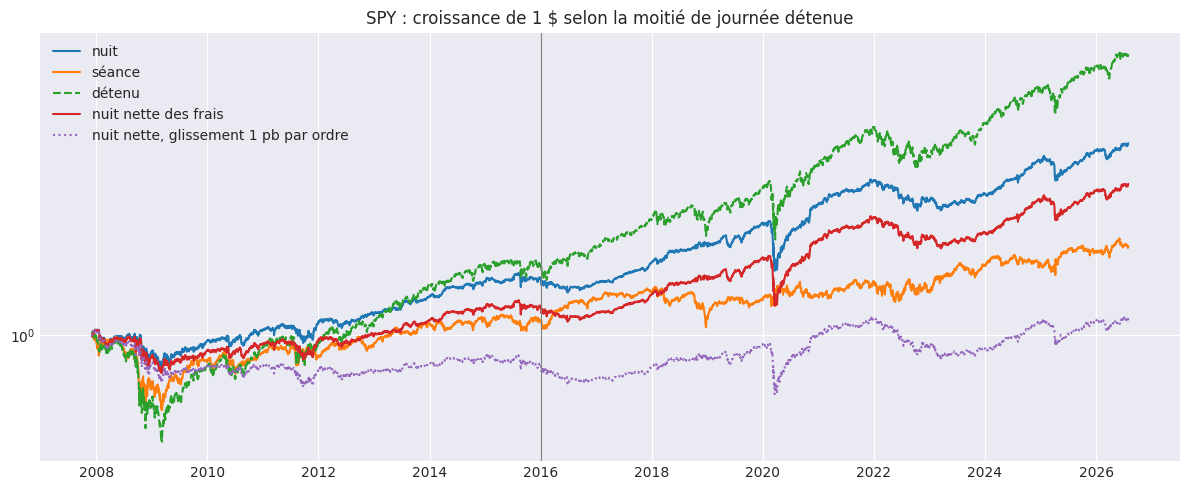

In [5]:
# Croissance de 1 $ : nuit brute, séance, titre détenu, nuit nette (échelle logarithmique)
fig, ax = plt.subplots(figsize=(12, 5))
for col, style in (("nuit", "-"), ("séance", "-"), ("détenu", "--")):
    ax.plot((1 + returns[col]).cumprod(), style, label=col)
ax.plot((1 + net["nuit nette des frais"]).cumprod(), "-", label="nuit nette des frais")
ax.plot((1 + net["nette, glissement 1.0 pb"]).cumprod(), ":", label="nuit nette, glissement 1 pb par ordre")
ax.axvline(pd.Timestamp("2016-01-01"), color="grey", lw=0.8)
ax.set_yscale("log")
ax.set_title("SPY : croissance de 1 $ selon la moitié de journée détenue")
ax.legend()
fig.tight_layout()
plt.show()

### Lecture du résultat

La courbe de la nuit (bleue) reste au-dessus de celle de la séance (orange) sur presque toute la fenêtre, et elle traverse 2008 avec une perte bien plus faible que le titre détenu (vert, en tirets). Mais le titre détenu, qui cumule les deux moitiés, finit loin devant. Les frais (rouge) ouvrent un écart qui grandit d'année en année, et un glissement de 1 pb par ordre (violet, en pointillés) ramène la nuit près de son point de départ : 13 % de gain en dix-huit ans et demi.

## 5. Règle de décision, écrite avant les backtests

La règle et les quatre bras ont été publiés sur l'issue #28404 avant le lancement des backtests QC Cloud de `main.py`.

- **Bras** : `overnight` (achat MOC envoyé 20 minutes avant la clôture, vente MOO envoyée 5 minutes après la clôture), `intraday` (le miroir), `hold` (la référence), et `overnight` sans frais (`fees=none`), qui mesure ce que coûtent les frais. SPY à la minute, cours bruts, 98 % du portefeuille engagés, barème de frais par action du courtier IB tel que Lean le modélise.
- **Fenêtres** : A = 2004-01-01 → 2015-12-31 (découverte), B = 2016-01-01 → 2026-07-31 (contrôle, lue après A).
- **Règle**, sur le Sharpe QC de `overnight` avec frais : `BEATS` s'il dépasse celui de `hold` sur A **et** sur B ; `NO BEATS` s'il est inférieur à celui de `hold` sur B ; `INCONCLUSIVE` dans les autres cas.
- **Prédictions**, qui ne changent pas la règle : sans frais, le CAGR de `overnight` dépasse celui d'`intraday` sur les deux fenêtres ; avec frais, le CAGR de `overnight` est sous celui de `hold` sur les deux fenêtres.
- **Hors mesure** : les ordres MOC et MOO sont remplis au prix d'enchère, sans écart entre prix acheteur et prix vendeur ; le glissement (`slip_bps`) reste une sensibilité, hors verdict.

## 6. Verdict des backtests QC Cloud

Les huit backtests (projet QC `OvernightAnomaly-QC`, données à la minute, ordres MOC et MOO) sont terminés, sans aucun ordre invalide.

| Bras | Fenêtre | Sharpe QC | CAGR (%) | Perte max. (%) | Frais (% du capital de départ) | Ordres |
|---|---|---|---|---|---|---|
| `overnight` | A | 0,140 | 4,33 | −31,9 | 27,56 | 6 041 |
| `overnight` sans frais | A | 0,293 | 6,29 | −30,2 | 0 | 6 041 |
| `intraday` | A | −0,166 | −1,02 | −45,1 | 18,96 | 6 040 |
| `hold` | A | 0,235 | 6,42 | −50,8 | 0,00 | 1 |
| `overnight` | B | 0,393 | 8,55 | −29,5 | 10,44 | 5 317 |
| `overnight` sans frais | B | 0,448 | 9,32 | −29,4 | 0 | 5 317 |
| `intraday` | B | 0,078 | 4,15 | −25,1 | 9,03 | 5 316 |
| `hold` | B | 0,573 | 13,89 | −31,5 | 0,00 | 1 |

**Verdict : NO BEATS.** Sur la fenêtre de contrôle B, le Sharpe de `overnight` avec frais (0,393) est inférieur à celui de `hold` (0,573). Il l'était déjà sur A (0,140 contre 0,235).

**Prédictions.** La seconde est tenue : avec frais, le CAGR de `overnight` reste sous celui de `hold` (4,33 % contre 6,42 % sur A, 8,55 % contre 13,89 % sur B). La première ne se tranche pas avec les backtests, parce que le bras `intraday` n'a tourné qu'avec frais. La comparaison sans frais des deux moitiés se lit dans le carnet : le CAGR de la nuit dépasse celui de la séance sur 2008-2015 (5,07 % contre 1,21 %) et sur 2016-2026 (9,36 % contre 5,10 %).

**Ce que coûtent les frais.** Le backtest recoupe l'article : 27,6 % du capital de départ en frais sur les douze ans de A, pour près de 25 % sur vingt ans dans l'article. Ils pèsent moins sur B (10,4 %), parce que le SPY y coûte plus cher et que les frais se paient par action. Sans frais, la nuit bat même `hold` en Sharpe sur A (0,293 contre 0,235), grâce à une perte maximale de −30 % contre −51 % : l'anomalie brute existe sur cette fenêtre, et ce sont les frais qui la font passer sous le titre détenu. Sur B, elle ne bat le titre détenu ni avant ni après frais.

## Conclusion

**Ce que montre le carnet.** Le rendement du SPY se fait surtout la nuit : 68 % du rendement logarithmique de fin 2007 à mi-2026, avec une volatilité inférieure d'un cinquième à celle de la séance. Le constat de l'article se retrouve sur les données LEAN.

**Ce qu'en fait une stratégie.** Négocier cette moitié coûte deux ordres par jour. Le barème par action ne prend que 0,6 pb par aller-retour en moyenne, mais l'avantage brut de la nuit sur le titre détenu est trop mince pour le supporter : dans les backtests QC Cloud, `overnight` reste sous `hold` en Sharpe et en CAGR sur les deux fenêtres. Verdict : **NO BEATS**, conforme à la conclusion de l'article.

**Limites.**

- Les ordres MOC et MOO sont remplis au prix d'enchère, sans écart entre prix acheteur et prix vendeur ni impact de marché. Le carnet montre qu'un glissement de 1 pb par ordre efface presque tout le rendement net : un remplissage réel ne peut que dégrader le résultat, il ne renverserait pas le verdict.
- Le Sharpe du carnet suppose un taux sans risque nul, celui de QC en déduit un : les deux ne se comparent qu'entre bras d'une même source.
- Le carnet couvre décembre 2007 → juillet 2026 ; la fenêtre A des backtests commence en 2004, quatre ans plus tôt.
- Seul le SPY est mesuré ; d'autres indices ou titres ne l'ont pas été.

**Suites possibles.** Mesurer la même décomposition sur un contrat à terme sur indice, qui se négocie aussi la nuit, ou n'acheter la nuit que les jours où un signal la rend plus favorable, ce qui réduit le nombre d'allers-retours.